In [4]:
from google.colab import files
import pandas as pd

# Upload CSV
uploaded = files.upload()

# Read
df = pd.read_csv(next(iter(uploaded)))
df.head()

Saving data_set (1).csv to data_set (1) (1).csv


,VDRL_RESULT,CONS_ALCOHOL,RH_FACTOR,SMOKER,PLAN_PREGNANCY,BLOOD_GROUP,HAS_PREG_RISK,TET_VACCINE,IS_HEAD_FAMILY,MARITAL_STATUS,...,HAS_FAM_INCOME,LEVEL_SCHOOLING,CONN_SEWER_NET,NUM_RES_HOUSEHOLD,HAS_FRU_TREE,HAS_VEG_GARDEN,FAM_INCOME,HOUSING_STATUS,WATER_TREATMENT,AGE
0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,...,0.0,5.0,0.0,2.0,1.0,1.0,0.0,1.0,2.0,25.0
1,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,5.0,...,0.0,5.0,0.0,2.0,1.0,1.0,2.0,1.0,3.0,25.0
2,1.0,1.0,2.0,1.0,1.0,4.0,1.0,0.0,1.0,5.0,...,1.0,6.0,2.0,4.0,1.0,1.0,3.0,0.0,3.0,24.0
3,1.0,1.0,2.0,1.0,0.0,4.0,0.0,0.0,1.0,5.0,...,0.0,2.0,1.0,3.0,1.0,1.0,0.0,0.0,2.0,28.0
4,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,...,1.0,4.0,1.0,3.0,1.0,1.0,0.0,0.0,3.0,27.0


Dataset Shape: (41762, 26)

Total Patients: 41762

Missing Values:

VDRL_RESULT          0
CONS_ALCOHOL         0
RH_FACTOR            0
SMOKER               0
PLAN_PREGNANCY       0
BLOOD_GROUP          0
HAS_PREG_RISK        0
TET_VACCINE          0
IS_HEAD_FAMILY       0
MARITAL_STATUS       0
FOOD_INSECURITY      0
NUM_ABORTIONS        0
NUM_LIV_CHILDREN     0
NUM_PREGNANCIES      0
FAM_PLANNING         0
TYPE_HOUSE           0
HAS_FAM_INCOME       0
LEVEL_SCHOOLING      0
CONN_SEWER_NET       0
NUM_RES_HOUSEHOLD    0
HAS_FRU_TREE         0
HAS_VEG_GARDEN       0
FAM_INCOME           0
HOUSING_STATUS       0
WATER_TREATMENT      0
AGE                  0
dtype: int64


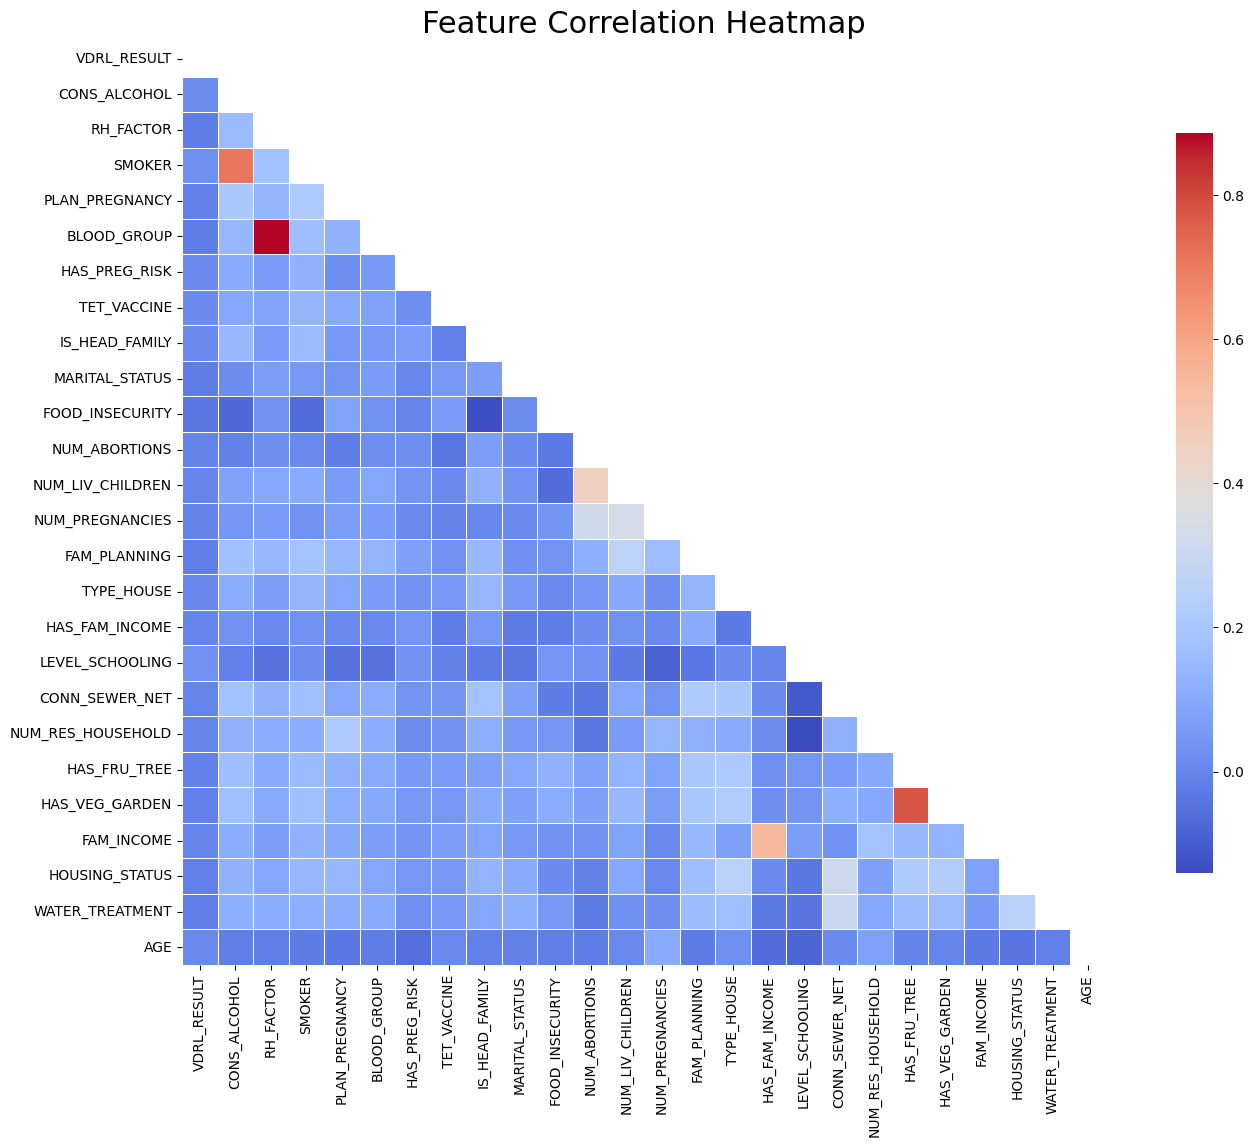

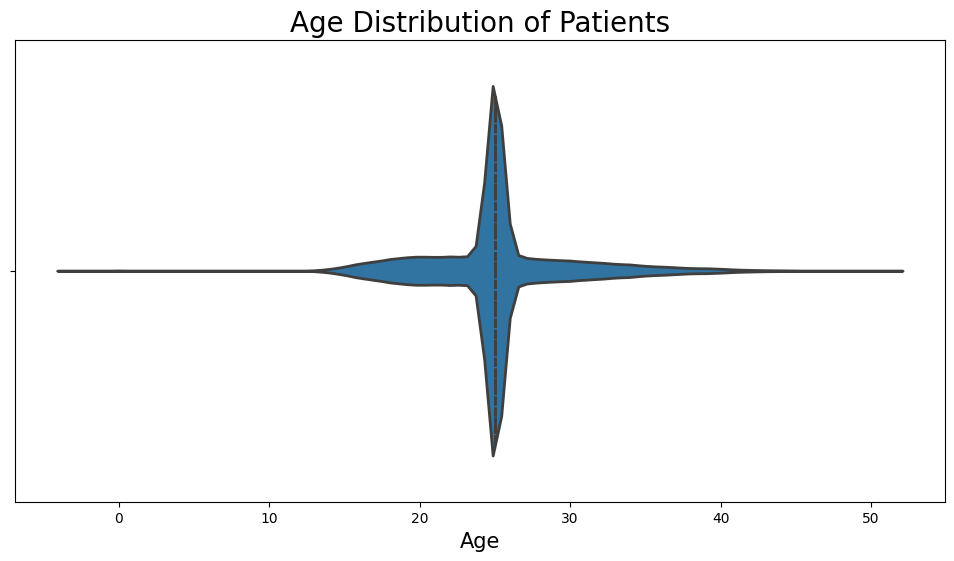

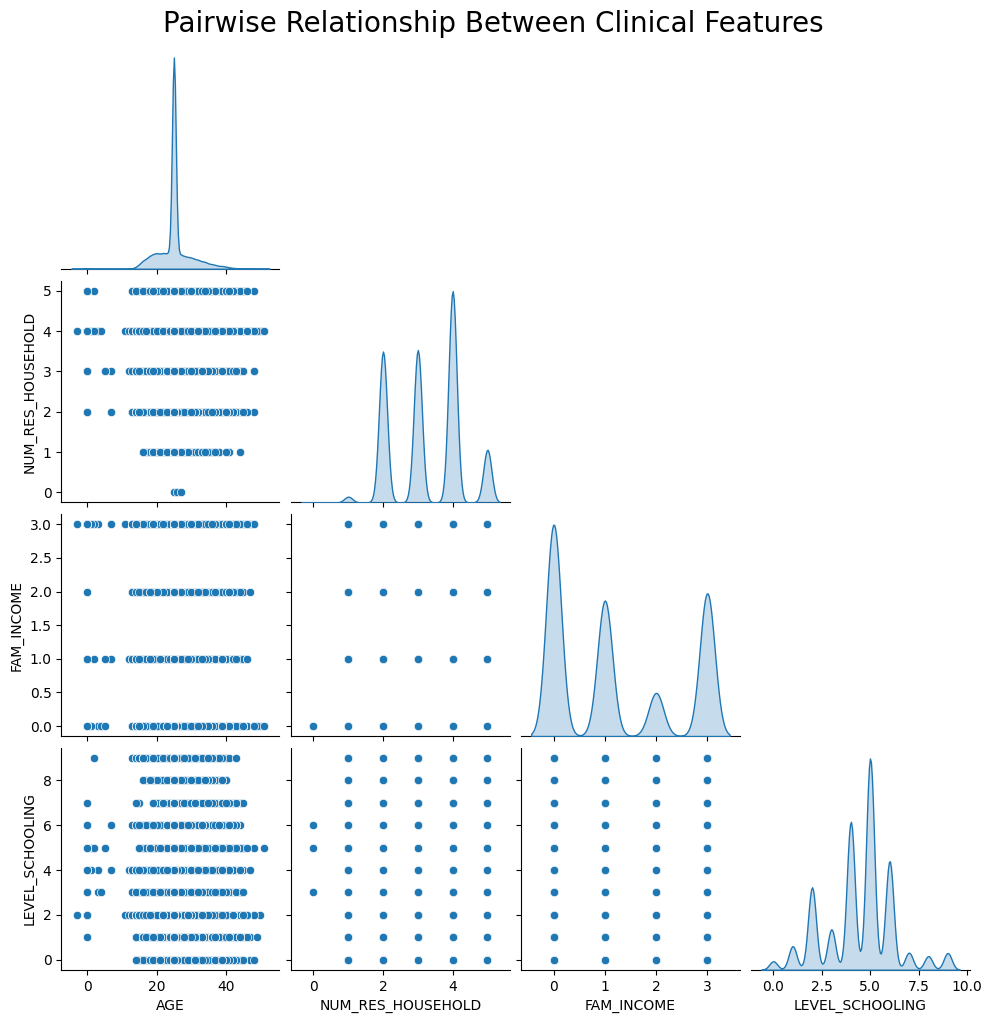

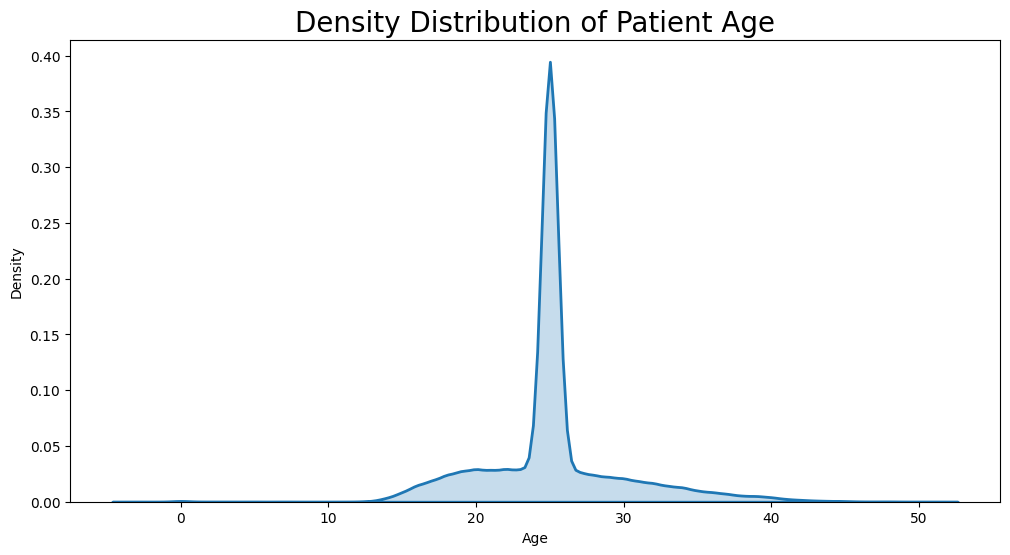

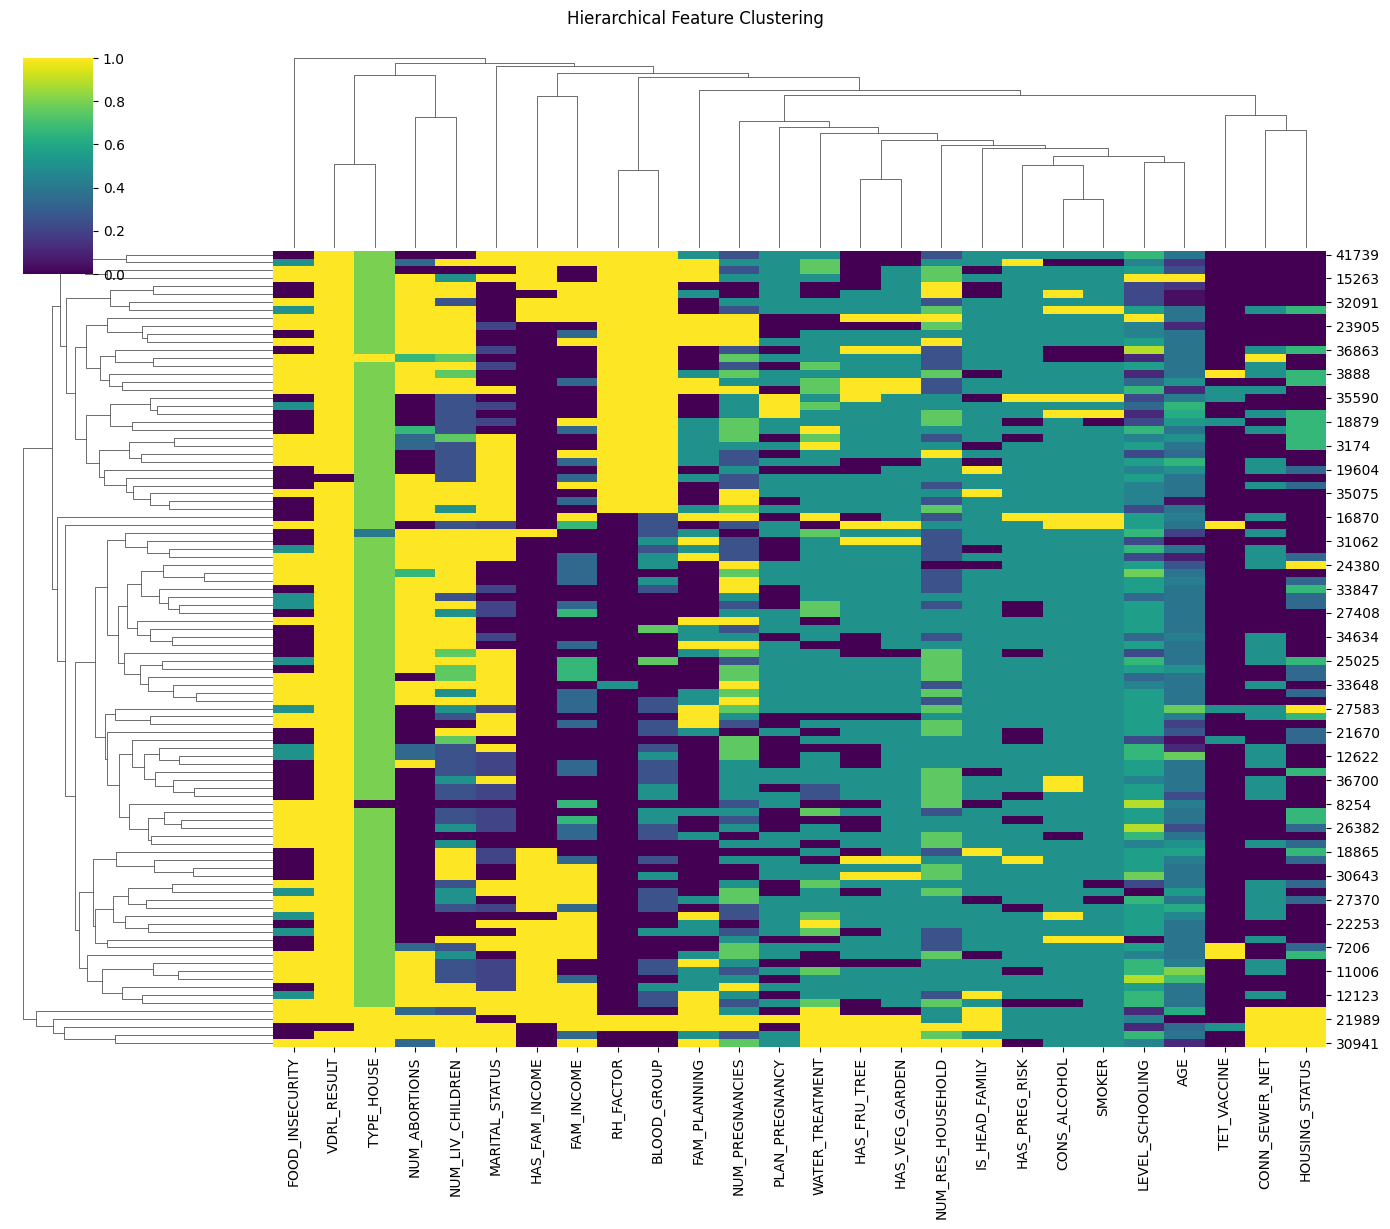

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Basic Dataset Statistics
print("Dataset Shape:", df.shape)
print("\nTotal Patients:", len(df))
print("\nMissing Values:\n")
print(df.isnull().sum())




#  Violin Plot for Age Distribution

plt.figure(figsize=(12,6))

sns.violinplot(
    x=df["AGE"],
    inner="quartile",
    linewidth=2
)

plt.title("Age Distribution of Patients", fontsize=20)
plt.xlabel("Age", fontsize=15)
plt.show()




# KDE Plot

plt.figure(figsize=(12,6))

sns.kdeplot(
    data=df,
    x="AGE",
    fill=True,
    linewidth=2
)

plt.title("Density Distribution of Patient Age", fontsize=20)
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()


# Fancy Cluster Map

sample_df = df.select_dtypes(include=np.number).sample(100)

sns.clustermap(
    sample_df,
    figsize=(14,12),
    cmap='viridis',
    standard_scale=1
)

plt.suptitle("Hierarchical Feature Clustering", y=1.02)
plt.show()

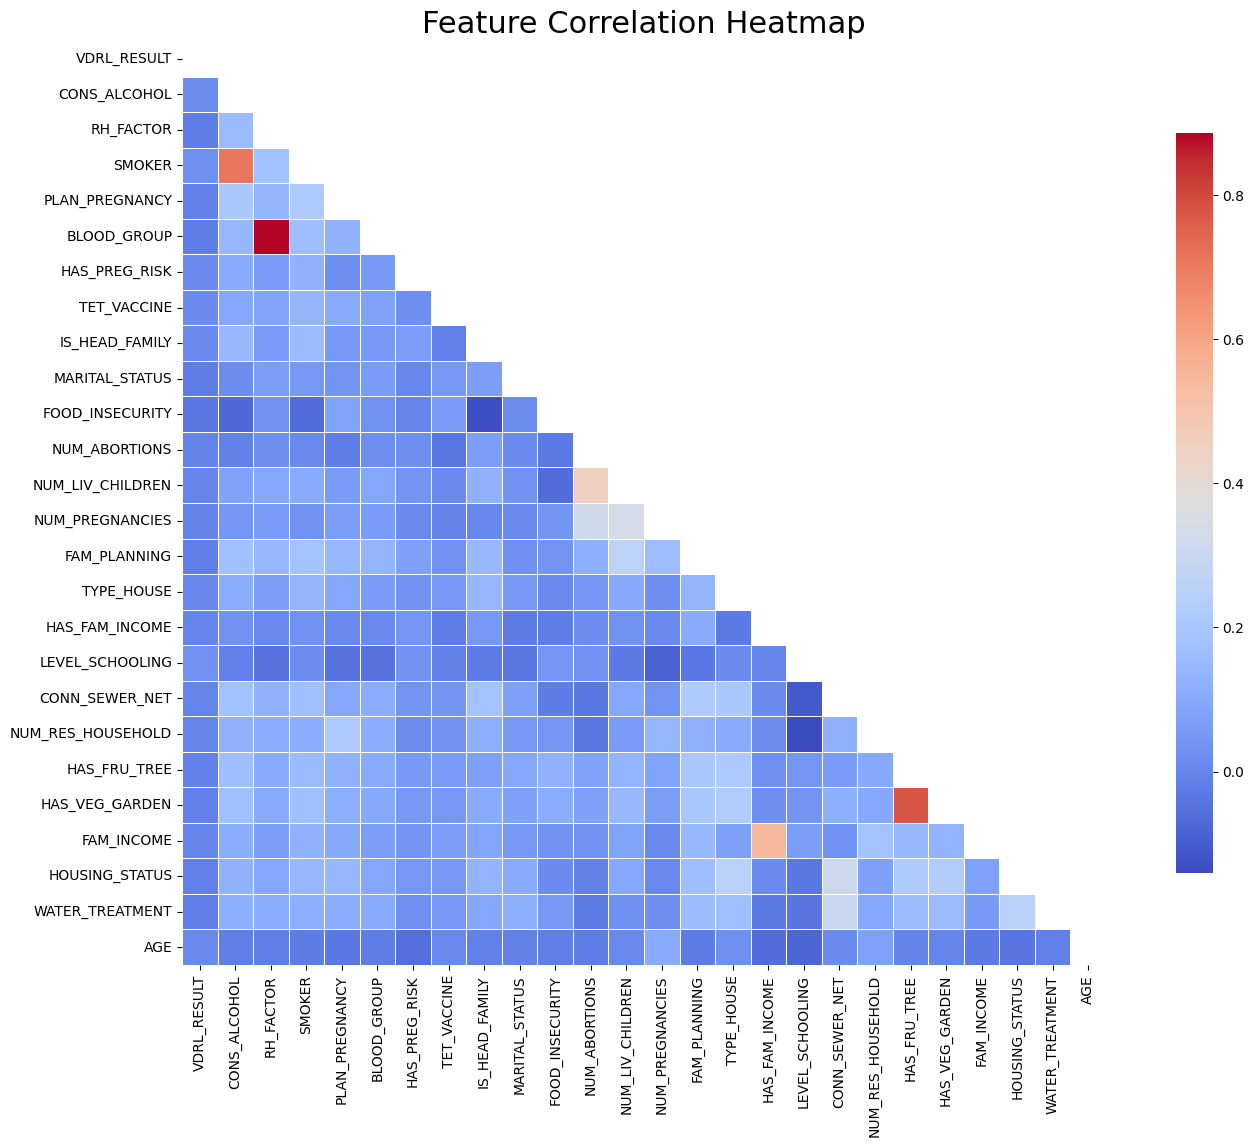

In [6]:
#  Correlation Heatmap

plt.figure(figsize=(18,12))

corr = df.corr(numeric_only=True)

mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": .8}
)

plt.title("Feature Correlation Heatmap", fontsize=22)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

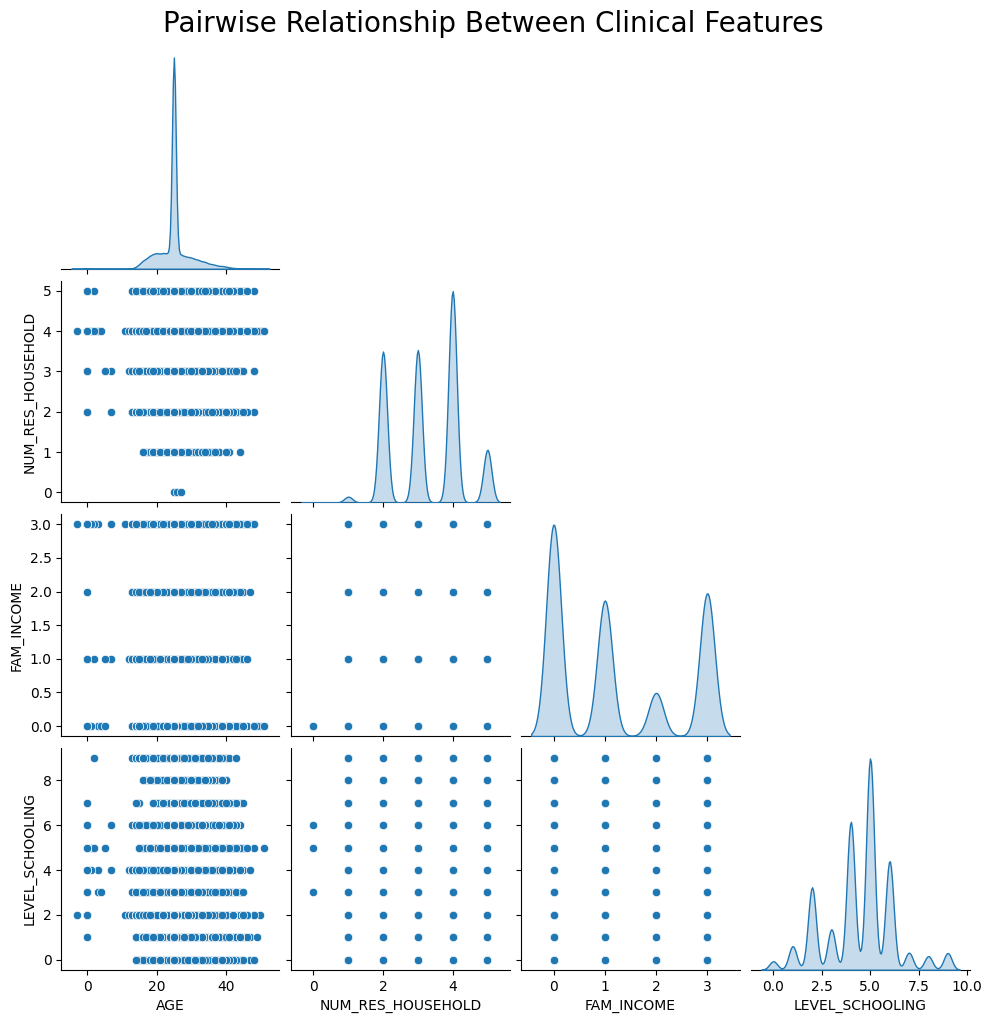

In [7]:

selected_features = [
    'AGE',
    'NUM_RES_HOUSEHOLD',
    'FAM_INCOME',
    'LEVEL_SCHOOLING'
]

sns.pairplot(
    df[selected_features],
    diag_kind='kde',
    corner=True
)

plt.suptitle("Pairwise Relationship Between Clinical Features", y=1.02, fontsize=20)
plt.show()